# Task 2 — Advanced EDA and Text Mining
**Purpose:** inspect the supplied HanuAi dataset, clean fields, extract transparent rule-based tags, classify issue themes, and cluster narrative text.

**Input:** `Hanuai_task2_assignment.csv` in the same folder. The rules are a baseline, not a validated engineering diagnosis. Treat category and root-cause interpretations as hypotheses requiring domain review.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import silhouette_score
from pathlib import Path

INPUT = Path("Hanuai_task2_assignment.csv")
df = pd.read_csv(INPUT)
print("Rows, columns:", df.shape)
display(df.head())
display(df.dtypes.to_frame("dtype"))

Rows, columns: (1000, 20)


,Event id,Opened date,CAUSAL_VERBATIM,CORRECTION_VERBATIM,CUSTOMER_VERBATIM,BUILD_DATE,BUILD_PLANT_DESC,CAUSAL_CD_DESC,COMPLAINT_CD_DESC,IN_USE_DATE,MAKE,MODEL,MODLYR,PLANT,Trigger,Failure Component,Failure Condition,Additional Context,Fix Component,Fix Condition
0,D-14801,9/17/2019,unable to duplicate the concern at this time r...,"waiting for techline engineering response, att...",Customer reports that radio and screen is inte...,2019-08-14T00:00:00.000Z,Flint,Module/Component-No/Incorrect Communication,Audio/Entertainment/Navigation - Other issues,2019-09-10T00:00:00.000Z,NovaSprint,AeroSpecter,2020,FLT,['No Additional Functionality'],"['Audio Unit', 'Display']","['Controls Irresponsive', 'Black Screen']",['No Additional Context'],"['Radio', 'SPS']","['Replaced', 'Programmed']"
1,D-14869,7/6/2020,upon inspection radio screen was found to be b...,and ground at radio as stated in service info ...,RADIO IS INOPERABLE CHECK AND ADVISE,2019-08-16T00:00:00.000Z,Fort Wayne,Module/Component-Shorted,Audio/Entertainment/Navigation - Other issues,2020-03-26T00:00:00.000Z,NebulaCruiser,StellarGlide,2020,FTW,['No Additional Functionality'],"['Radio', 'Display', 'Radio']","['Inoperative', 'Black Screen', 'No Sound']",['No Additional Context'],"['Radio', 'USB']","['Replaced', 'Programmed']"
2,D-14555,1/9/2020,Scanned found no codes checked for bulletins f...,radio module internal failure,CUSTOMER STATES RADIO SCREEN AND ONSTAR KEEPS ...,2019-08-06T00:00:00.000Z,Flint,Module/Component-Worn/Stripped,Audio/Entertainment/Navigation - Other issues,2019-11-29T00:00:00.000Z,ThunderVolt,HyperFury X,2020,FLT,['No Additional Functionality'],"['Display', 'OnStar', 'Radio Module']","['Inoperative', 'Inoperative', 'Internal Fault']",['No Additional Context'],['Radio'],['Replaced']
3,D-14704,4/14/2020,"PANTALLA SE PONE NEGRA, LO QUE PROVOCA QUE AL ...",DESPUES DE REALIZAR LA INPECCION VISUAL Y OPER...,PANTALLA SE PONE NEGRA,2019-08-12T00:00:00.000Z,Spring Hill - Truck,Module/Component-No/Incorrect Communication,Features/Controls/Displays - Other issues,2019-12-26T00:00:00.000Z,ThunderVolt,HyperFury X,2020,SHT,['When Reversing'],['Display'],['Black Screen'],['While Driving'],"['Radio', 'USB']","['Replaced', 'Programmed']"
4,D-15142,11/23/2020,INSPECTED VEHICLE AND CONFIRMED THAT THE...,SCRANNED FOR CODES NONE FOUND FOUND UPDATE N...,CUSTOMER STATES A MESSAGE OF LOST SATELITE SIG...,2019-08-27T00:00:00.000Z,Fort Wayne,Module/Component-Registers Incorrectly,Audio/Entertainment/Navigation - Other issues,2019-10-31T00:00:00.000Z,ThunderVolt,TurboFlare,2020,FTW,['No Additional Functionality'],['Radio'],['Malfunction'],['No Additional Context'],['Radio'],['Replaced']


,dtype
Event id,str
Opened date,str
CAUSAL_VERBATIM,str
CORRECTION_VERBATIM,str
CUSTOMER_VERBATIM,str
BUILD_DATE,str
BUILD_PLANT_DESC,str
CAUSAL_CD_DESC,str
COMPLAINT_CD_DESC,str
IN_USE_DATE,str


## 1. Data quality assessment

In [8]:
# Missingness and exact duplicate checks
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(1)
display(pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct}))
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate event IDs:", df["Event id"].duplicated().sum())
display(df.describe(include="all").T)

,missing_count,missing_pct
Fix Component,995,99.5
Fix Condition,995,99.5
Additional Context,995,99.5
Failure Condition,995,99.5
Trigger,995,99.5
Failure Component,995,99.5
CAUSAL_CD_DESC,3,0.3
CAUSAL_VERBATIM,1,0.1
IN_USE_DATE,1,0.1
CORRECTION_VERBATIM,0,0.0


Exact duplicate rows: 0
Duplicate event IDs: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Event id,1000,1000,D-14801,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Opened date,1000,397,3/15/2021,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CAUSAL_VERBATIM,999,944,RADIO,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CORRECTION_VERBATIM,1000,952,REPLACED RADIO,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CUSTOMER_VERBATIM,1000,990,Audio Entertainment Navigation Other issues,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BUILD_DATE,1000,37,2019-08-28T00:00:00.000Z,51,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BUILD_PLANT_DESC,1000,8,Fort Wayne,217,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CAUSAL_CD_DESC,997,38,Module/Component-No/Incorrect Communication,377,NaN,NaN,NaN,NaN,NaN,NaN,NaN
COMPLAINT_CD_DESC,1000,9,Audio/Entertainment/Navigation - Audio,337,NaN,NaN,NaN,NaN,NaN,NaN,NaN
IN_USE_DATE,999,285,2019-10-31T00:00:00.000Z,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
# Parse dates without silently replacing invalid values.
for col in ["Opened date", "BUILD_DATE", "IN_USE_DATE"]:
    if col in df.columns:
        df[col + "_parsed"] = pd.to_datetime(df[col], errors="coerce")
# Narrative columns are kept as text; missing values become empty strings only in derived text.
text_cols = ["CUSTOMER_VERBATIM", "CAUSAL_VERBATIM", "CORRECTION_VERBATIM"]
for col in text_cols:
    df[col] = df[col].fillna("").astype(str).str.replace(r"\\s+", " ", regex=True).str.strip()
df["TEXT_COMBINED"] = df[text_cols].agg(" ".join, axis=1).str.replace(r"\\s+", " ", regex=True).str.strip()
print("Rows with empty combined narrative:", (df["TEXT_COMBINED"] == "").sum())

Rows with empty combined narrative: 0


## 2. Stakeholder-focused EDA

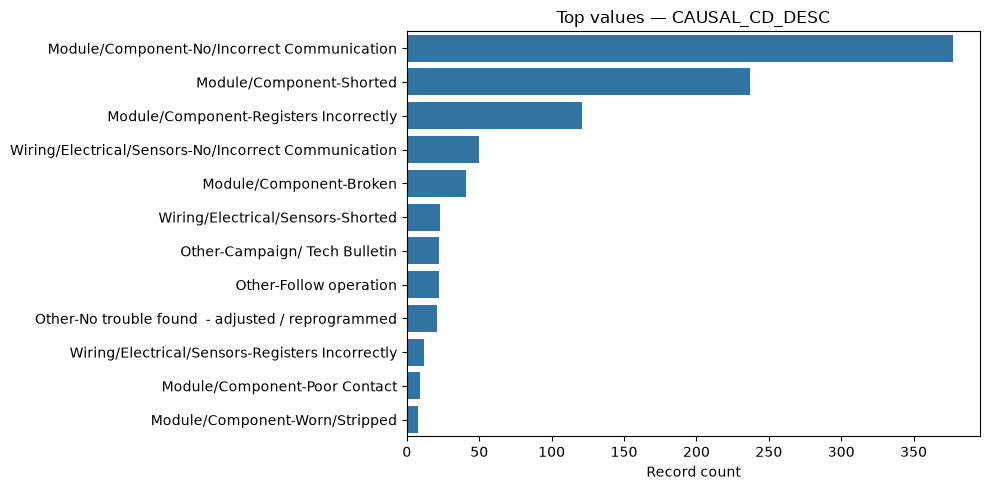

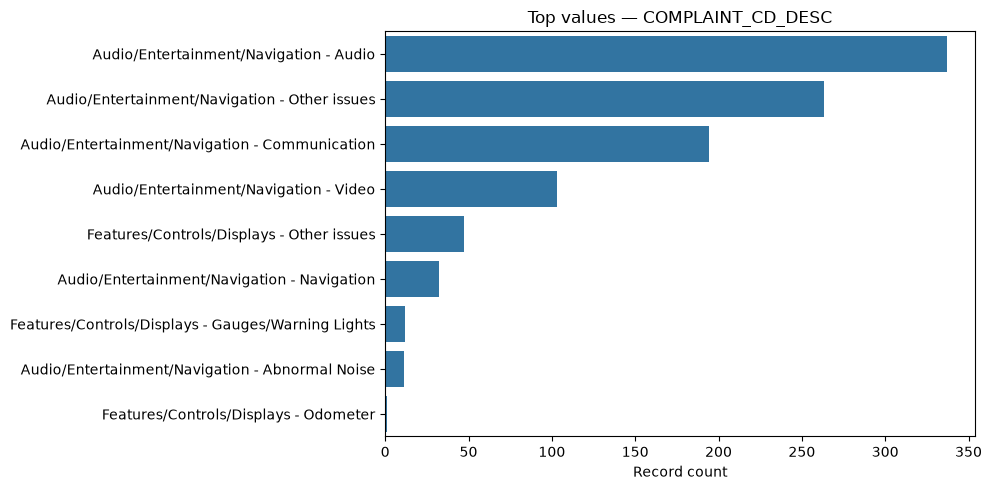

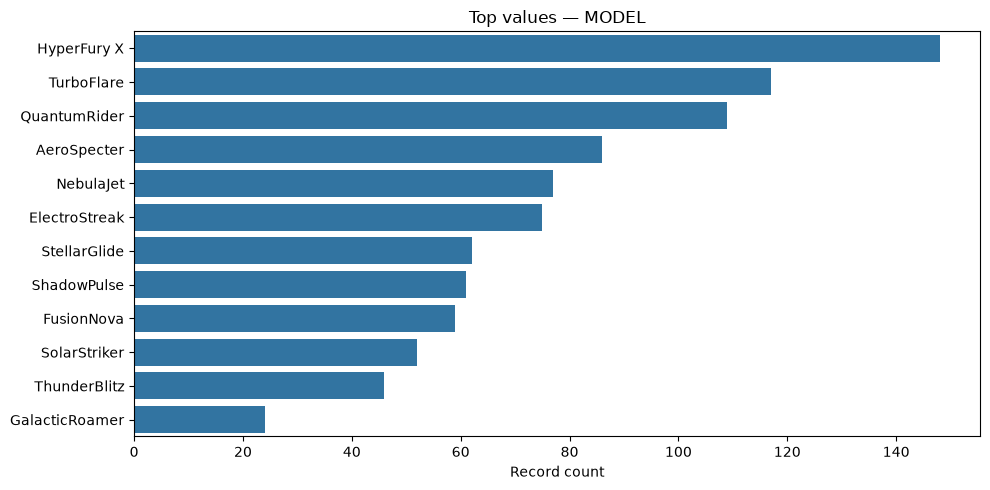

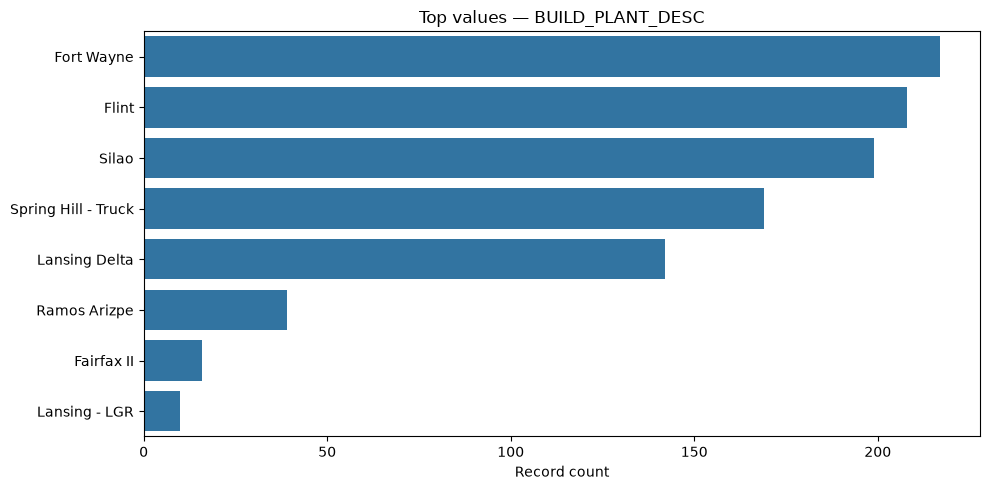

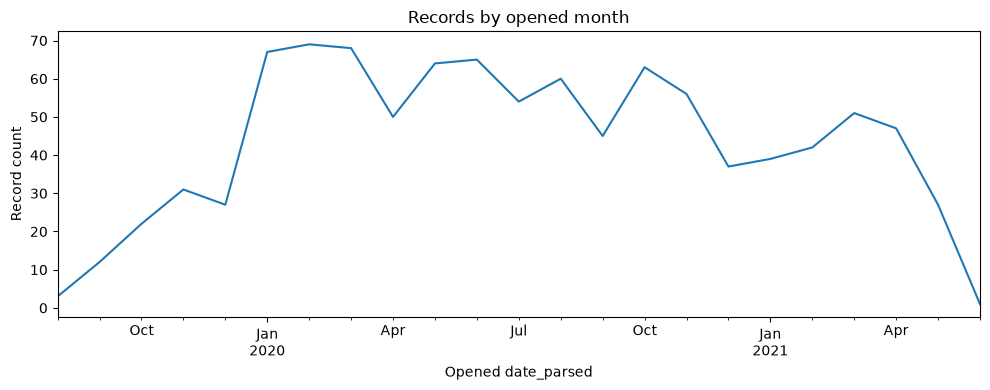

In [10]:
# Frequency plots for key categorical fields
for col in ["CAUSAL_CD_DESC", "COMPLAINT_CD_DESC", "MODEL", "BUILD_PLANT_DESC"]:
    if col in df.columns:
        counts = df[col].fillna("Missing").value_counts().head(12)
        plt.figure(figsize=(10, 5))
        sns.barplot(x=counts.values, y=counts.index)
        plt.title(f"Top values — {col}")
        plt.xlabel("Record count")
        plt.ylabel("")
        plt.tight_layout()
        plt.show()

# Opened-date trend by month (invalid dates excluded)
if "Opened date_parsed" in df.columns:
    monthly = df.dropna(subset=["Opened date_parsed"]).set_index("Opened date_parsed").resample("MS").size()
    monthly.plot(figsize=(10,4), title="Records by opened month")
    plt.ylabel("Record count")
    plt.tight_layout()
    plt.show()

## 3. Entity tags and issue grouping
The rule-based extraction below is intentionally interpretable. Add domain vocabulary after reviewing representative records; do not treat keywords as proof of root cause.

In [11]:
import json
TAG_TERMS = {
    "Display": ["display", "screen", "black screen", "blank screen", "backup camera"],
    "Radio / Audio": ["radio", "audio", "no sound", "speaker", "satellite radio"],
    "Connectivity": ["communication", "disconnect", "reconnect", "signal", "ethernet", "onstar", "wifi"],
    "Electrical / Wiring": ["connector", "terminal", "wiring", "coax", "cable", "ground", "resistance"],
    "Software / Programming": ["programming", "software", "update", "reprogram", "reset", "dtc"],
    "USB / SD Media": ["usb", "sd card", "card reader"],
    "Intermittent": ["intermittent", "intermittently", "persists", "comes back"],
    "Replacement / Repair": ["replaced", "replace", "installed", "repair"]
}
def extract_tags(text):
    t = str(text).lower()
    return [tag for tag, terms in TAG_TERMS.items() if any(term in t for term in terms)]

ISSUE_RULES = {
    "Display / Screen": ["black screen", "blank screen", "screen", "display", "back up camera", "camera inop"],
    "Audio / Radio": ["no audio", "no sound", "radio", "satellite radio", "audio cut", "speaker"],
    "Connectivity / Communication": ["lost communication", "communication", "disconnect", "reconnect", "signal lost", "ethernet bus", "wifi", "onstar"],
    "Electrical / Wiring": ["connector", "terminal", "wiring", "coax", "cable", "ground", "short circuit", "open condition", "high resistance"],
    "Software / Programming": ["program", "update", "software", "reflash", "programming", "reset", "dtc", "code"],
    "Storage / Media": ["sd card", "usb port", "usb cable", "usb"]
}
def classify_issue(text):
    t = str(text).lower()
    for category, terms in ISSUE_RULES.items():
        if any(term in t for term in terms):
            return category
    return "Unclassified / Needs Review"

df["EXTRACTED_TAGS"] = df["TEXT_COMBINED"].apply(lambda x: json.dumps(extract_tags(x)))
df["ISSUE_CATEGORY"] = df["TEXT_COMBINED"].apply(classify_issue)
df["TEXT_LENGTH"] = df["TEXT_COMBINED"].str.len()
display(df[["Event id", "EXTRACTED_TAGS", "ISSUE_CATEGORY", "TEXT_LENGTH"]].head())

,Event id,EXTRACTED_TAGS,ISSUE_CATEGORY,TEXT_LENGTH
0,D-14801,"[""Display"", ""Radio / Audio"", ""Connectivity"", ""...",Display / Screen,2339
1,D-14869,"[""Display"", ""Radio / Audio"", ""Connectivity"", ""...",Display / Screen,2212
2,D-14555,"[""Display"", ""Radio / Audio"", ""Connectivity"", ""...",Display / Screen,2146
3,D-14704,"[""Radio / Audio"", ""Electrical / Wiring"", ""Soft...",Audio / Radio,2065
4,D-15142,"[""Display"", ""Radio / Audio"", ""Connectivity"", ""...",Display / Screen,2062


,record_count
ISSUE_CATEGORY,
Display / Screen,505
Audio / Radio,487
Unclassified / Needs Review,3
Software / Programming,2
Electrical / Wiring,1
Connectivity / Communication,1
Storage / Media,1


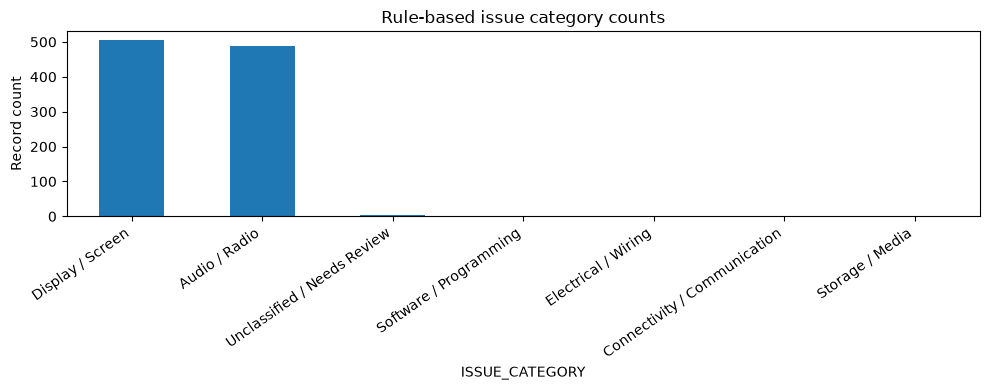

,tag_count
Radio / Audio,990
Replacement / Repair,903
Software / Programming,564
Display,487
USB / SD Media,342
Connectivity,323
Electrical / Wiring,312
Intermittent,106


In [12]:
# Issue category frequency
issue_counts = df["ISSUE_CATEGORY"].value_counts()
display(issue_counts.to_frame("record_count"))
issue_counts.plot(kind="bar", figsize=(10,4), title="Rule-based issue category counts")
plt.ylabel("Record count")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# Tags are multi-label, so a record may contribute to several tags.
tag_counts = pd.Series([tag for row in df["EXTRACTED_TAGS"] for tag in json.loads(row)]).value_counts()
display(tag_counts.to_frame("tag_count"))

## 4. TF-IDF and K-Means clustering

In [13]:
# Exclude empty text and short records; use a modest number of clusters for exploration.
valid = df["TEXT_COMBINED"].str.strip().ne("")
texts = df.loc[valid, "TEXT_COMBINED"]
vectorizer = TfidfVectorizer(stop_words="english", max_features=3000, ngram_range=(1,2), min_df=2)
X = vectorizer.fit_transform(texts)
if X.shape[0] >= 3:
    k = min(5, max(2, X.shape[0] // 50))
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X)
    df["TEXT_CLUSTER"] = np.nan
    df.loc[valid, "TEXT_CLUSTER"] = labels
    terms = np.array(vectorizer.get_feature_names_out())
    for i, center in enumerate(model.cluster_centers_):
        top = center.argsort()[-10:][::-1]
        print(f"Cluster {i}: " + ", ".join(terms[top]))
    print("Cluster sizes:")
    display(df.loc[valid, "TEXT_CLUSTER"].value_counts().sort_index().to_frame("records"))
else:
    print("Not enough non-empty records for clustering.")

Cluster 0: radio, replace, replace radio, tac, program, check, case, customer, screen, codes
Cluster 1: card, sd, sd card, error, navigation, radio, error code, nav, message, usb
Cluster 2: camera, radio, rear, coax, camera inop, video, backup, backup camera, cable, inop
Cluster 3: radio, update, xm, usb, software, performed, customer, vehicle, code, phone
Cluster 4: radio, replaced, screen, replaced radio, internal, customer, programmed, module, states, tested
Cluster sizes:


,records
TEXT_CLUSTER,
0.0,286
1.0,46
2.0,95
3.0,232
4.0,341


## 5. Export enriched data and summary
Review the outputs before stakeholder use. Rule-based categories and clusters are exploratory and should be validated against a manually labeled sample.

In [14]:
out = Path("task2_tagged_dataset.csv")
df.to_csv(out, index=False)
print("Saved:", out.resolve())
print("Top issue categories:")
display(df["ISSUE_CATEGORY"].value_counts().head(10))
print("Missingness after text normalization:")
display(df.isna().sum().sort_values(ascending=False).head(10).to_frame("missing"))

Saved: E:\HanuAi_ML_nxtwave assignment\task2_tagged_dataset.csv
Top issue categories:


ISSUE_CATEGORY
Display / Screen                505
Audio / Radio                   487
Unclassified / Needs Review       3
Software / Programming            2
Electrical / Wiring               1
Connectivity / Communication      1
Storage / Media                   1
Name: count, dtype: int64

Missingness after text normalization:


,missing
Failure Condition,995
Additional Context,995
Trigger,995
Failure Component,995
Fix Condition,995
Fix Component,995
CAUSAL_CD_DESC,3
IN_USE_DATE_parsed,1
IN_USE_DATE,1
CORRECTION_VERBATIM,0
